<a href="https://colab.research.google.com/github/VelikiyVor/cookie-cats-ab-test/blob/main/cookie_cats_ab_test.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Cookie Cats A/B Test: Gate at Level 30 vs Level 40

Does moving the first gate from level 30 to level 40 change player retention? 90,189 players, randomly assigned at install.

**Data:** [Kaggle – Mobile Games A/B Testing: Cookie Cats](https://www.kaggle.com/datasets/mursideyarkin/mobile-games-ab-testing-cookie-cats). The first code cell asks you to upload `cookie_cats.csv` if it isn't loaded yet.

## 0. Setup

In [1]:
import os
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep

if not os.path.exists("cookie_cats.csv"):
    from google.colab import files
    files.upload()  # choose cookie_cats.csv

df = pd.read_csv("cookie_cats.csv")
df.head()

Saving cookie_cats.csv to cookie_cats.csv


,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


## 1. Sanity checks
Check the data is complete, the groups are evenly split, and remove extreme outliers.

In [2]:
print(df.shape, "| missing values:", df.isna().sum().sum())
counts = df["version"].value_counts()
print(counts)
_, p_srm = stats.chisquare(counts)
print(f"Sample ratio mismatch p-value: {p_srm:.3f}  (>0.05 = groups are balanced)")

print(df["sum_gamerounds"].describe())
df = df[df["sum_gamerounds"] != df["sum_gamerounds"].max()]   # drop the one extreme outlier

(90189, 5) | missing values: 0
version
gate_40    45489
gate_30    44700
Name: count, dtype: int64
Sample ratio mismatch p-value: 0.009  (>0.05 = groups are balanced)
count    90189.000000
mean        51.872457
std        195.050858
min          0.000000
25%          5.000000
50%         16.000000
75%         51.000000
max      49854.000000
Name: sum_gamerounds, dtype: float64


## 2. Topline metrics
Day 1 and Day 7 retention and median rounds played, by group.

In [3]:
summary = df.groupby("version").agg(
    players=("userid", "count"),
    d1_retention=("retention_1", "mean"),
    d7_retention=("retention_7", "mean"),
    median_rounds=("sum_gamerounds", "median"),
)
summary

,players,d1_retention,d7_retention,median_rounds
version,,,,
gate_30,44699,0.448198,0.190183,17.0
gate_40,45489,0.442283,0.182000,16.0


## 3. Significance tests
Two-proportion z-test and 95% confidence interval on the difference (gate_40 minus gate_30).

In [4]:
for m in ["retention_1", "retention_7"]:
    g = df.groupby("version")[m]
    succ = g.sum()[["gate_40", "gate_30"]].values
    nobs = g.count()[["gate_40", "gate_30"]].values
    _, p = proportions_ztest(succ, nobs)
    lo, hi = confint_proportions_2indep(succ[0], nobs[0], succ[1], nobs[1])
    diff = succ[0] / nobs[0] - succ[1] / nobs[1]
    print(f"{m}: diff = {diff*100:+.2f} pp, 95% CI [{lo*100:+.2f}, {hi*100:+.2f}], p = {p:.4f}")

retention_1: diff = -0.59 pp, 95% CI [-1.24, +0.06], p = 0.0739
retention_7: diff = -0.82 pp, 95% CI [-1.33, -0.31], p = 0.0016


## 4. Bootstrap
Resample each group 2,000 times to see how often gate_30 comes out ahead.

retention_1: P(gate_30 better) = 96.6%
retention_7: P(gate_30 better) = 100.0%


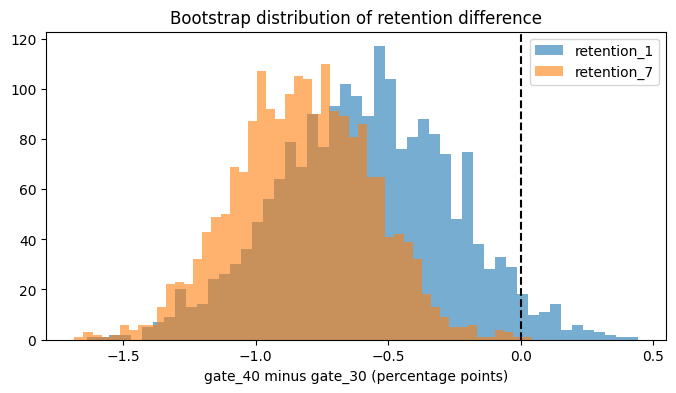

In [5]:
rng = np.random.default_rng(42)
g30, g40 = df[df.version == "gate_30"], df[df.version == "gate_40"]
fig, ax = plt.subplots(figsize=(8, 4))
for m in ["retention_1", "retention_7"]:
    x30, x40 = g30[m].to_numpy(), g40[m].to_numpy()
    diffs = np.array([rng.choice(x40, x40.size).mean() - rng.choice(x30, x30.size).mean()
                      for _ in range(2000)]) * 100
    print(f"{m}: P(gate_30 better) = {(diffs < 0).mean():.1%}")
    ax.hist(diffs, bins=50, alpha=0.6, label=m)
ax.axvline(0, color="black", ls="--")
ax.set_xlabel("gate_40 minus gate_30 (percentage points)")
ax.set_title("Bootstrap distribution of retention difference")
ax.legend(); plt.show()

## 5. Engagement
Rounds played are heavily skewed, so we use a Mann-Whitney U test instead of a t-test.

In [6]:
_, p_mw = stats.mannwhitneyu(g30["sum_gamerounds"], g40["sum_gamerounds"])
print(f"Game rounds Mann-Whitney p-value: {p_mw:.4f}")

Game rounds Mann-Whitney p-value: 0.0509


## 6. Recommendation
- **Don't ship gate_40.** Day 7 retention falls 0.82 pp (p = 0.002; gate_30 better in >99.9% of bootstrap resamples). Day 1 retention and rounds played point the same way but aren't significant at 5%.
- **Investigate the test setup.** The groups are uneven (45,489 vs 44,700; SRM p = 0.009), which suggests an assignment or logging issue.
- **Next test:** the dataset has no revenue. A follow-up should use ARPDAU as the primary metric, with Day 7 retention as a guardrail.